## YOLO

In [ ]:
import json
import logging
import random
import shutil
from contextlib import contextmanager
from pathlib import Path
 
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from ultralytics import YOLO
 
 
# --- Modo de ejecución -------------------------------------------------------
ENTRENAR = False          # para cargar el entrenamiento ya hecho o realizar un entrenamiento
RUN_A_CARGAR = None       # nombre de la carpeta dentro de runs/ a cargar.
                         
# --- Rutas -------------------------------------------------------------------
DATASET_DIR = Path(r"C:\Users\alici\Downloads\Imagenes VC")   # este path es en mi ordenador
IMAGES_DIR = DATASET_DIR / "images"
ANNOTATIONS_DIR = DATASET_DIR / "annotations"
 
OUTPUT_DIR = Path("dataset_yolo")        # dataset en formato YOLO (se genera en la celda 3)
RUNS_DIR = Path("runs").resolve()        # entrenamientos y evaluaciones
RUN_NAME = "matriculas_yolo11n_1280"     # nombre para cambiarlo en cada entrenamiento y se generen las carpetas
 
# --- Dataset -----------------------------------------------------------------
SEED = 42                                           # semilla: misma división siempre
SPLITS = {"train": 0.70, "val": 0.15, "test": 0.15} # proporciones sobre nº de imágenes
IMAGE_EXTENSIONS = {".jpg", ".jpeg"}
INCLUIR_SIN_ANOTACION = True    # imágenes sin .json se usan como fondo (sin matrículas)
MIN_ANCHO_REL = 0.01            # descartar matrículas con ancho < 1 % del de la imagen
 
# --- Entrenamiento -----------------------------------------------------------
MODELO_BASE = "yolo11n.pt"      # pesos preentrenados en COCO (fine-tuning)
EPOCHS = 120
PATIENCE = 20                   # early stopping: si val no mejora en 20 épocas
IMGSZ = 1280                    # resolución de entrada
BATCH = 8                       # fijo para no superar los 6 GB de VRAM a 1280
WORKERS = 4                     
 
# --- Evaluación --------------------------------------------------------------
CONF_UMBRAL = 0.35              # umbral de confianza
 
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
 

PyTorch: 2.5.1+cu121 | CUDA: True | NVIDIA GeForce RTX 3050


In [ ]:
# 2. Funciones auxiliares

# Lee un JSON de anotaciones y devuelve las cajas (xc, yc, w, h) normalizadas en [0, 1]
def leer_anotaciones(json_path, img_w, img_h):
    with open(json_path, "r", encoding="utf-8-sig") as f:
        data = json.load(f)
    if isinstance(data, dict):                                # por si algún JSON no es lista
        data = data.get("annotations", [data])
 
    cajas = []
    for ann in data:
        xc, yc, w, h = map(float, ann["rectangle"])
        if max(xc, yc, w, h) > 1.0:                           # coordenadas en píxeles
            xc, w = xc / img_w, w / img_w
            yc, h = yc / img_h, h / img_h
 
        x1, y1 = max(0.0, xc - w / 2), max(0.0, yc - h / 2)
        x2, y2 = min(1.0, xc + w / 2), min(1.0, yc + h / 2)
        if x2 - x1 <= 0 or y2 - y1 <= 0:                      # caja degenerada
            continue
        if x2 - x1 < MIN_ANCHO_REL:                           # matrícula ilegible
            continue
        cajas.append(((x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1))
    return cajas


# Guarda la imagen con su lado mayor reducido a lado_max
def copiar_redimensionada(src, dst, lado_max=IMGSZ):
    img = cv2.imdecode(np.fromfile(str(src), dtype=np.uint8), cv2.IMREAD_COLOR)
    h, w = img.shape[:2]
    s = lado_max / max(h, w)
    if s < 1:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 95])[1].tofile(str(dst))


# (Re)escribe data.yaml con la ruta absoluta de ESTE ordenador.
def escribir_data_yaml():
    yaml_path = OUTPUT_DIR.resolve() / "data.yaml"
    yaml_path.write_text(
        f"path: {OUTPUT_DIR.resolve().as_posix()}\n"
        "train: images/train\n"
        "val: images/val\n"
        "test: images/test\n"
        "names:\n"
        "  0: plate\n"
    )
    return yaml_path


# Devuelve la imagen (RGB) con las cajas de su archivo de etiquetas YOLO dibujadas
def dibujar_etiquetas(img_path, label_path, color=(0, 255, 0)):
    img = cv2.imdecode(np.fromfile(str(img_path), dtype=np.uint8), cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    for linea in Path(label_path).read_text().splitlines():
        _, xc, yc, w, h = map(float, linea.split())
        x1, y1 = int((xc - w / 2) * W), int((yc - h / 2) * H)
        x2, y2 = int((xc + w / 2) * W), int((yc + h / 2) * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 3)
    return img


# Muestra una de las gráficas que genera Ultralytics 
def mostrar_png(path, titulo=None):
    path = Path(path)
    if not path.exists():
        print("No encontrado:", path)
        return
    plt.figure(figsize=(10, 7))
    plt.imshow(plt.imread(path))
    plt.title(titulo or path.name)
    plt.axis("off")
    plt.show()


#Tabla con los entrenamientos de RUNS_DIR: épocas y mejor mAP en validación
def listar_entrenamientos():
    filas = []
    for csv in RUNS_DIR.glob("*/results.csv"):
        if not (csv.parent / "weights" / "best.pt").exists():
            continue
        df = pd.read_csv(csv)
        df.columns = df.columns.str.strip()
        filas.append({
            "carpeta": csv.parent.name,
            "épocas": len(df),
            "mejor mAP50": df["metrics/mAP50(B)"].max(),
            "mejor mAP50-95": df["metrics/mAP50-95(B)"].max(),
        })
    return pd.DataFrame(filas).sort_values("mejor mAP50-95", ascending=False).reset_index(drop=True)


# Oculta temporalmente los mensajes de Ultralytics para no ensuciar la salida
@contextmanager
def silenciar_ultralytics():
    """"""
    logger = logging.getLogger("ultralytics")
    nivel = logger.level
    logger.setLevel(logging.WARNING)
    try:
        yield
    finally:
        logger.setLevel(nivel)


# Evalúa el modelo en un split y devuelve un diccionario con todas las métricas
def evaluar(model, split):
    comunes = dict(data=str(DATA_YAML), split=split, imgsz=IMGSZ, device=DEVICE,
                   plots=True, verbose=False, project=str(RUNS_DIR), exist_ok=True)
    with silenciar_ultralytics():
        m = model.val(name=f"{TRAIN_DIR.name}_{split}", **comunes)
        m2 = model.val(name=f"{TRAIN_DIR.name}_{split}_conf{CONF_UMBRAL}",
                       conf=CONF_UMBRAL, **comunes)
 
    P, R = m.box.mp, m.box.mr
    cm = m2.confusion_matrix.matrix              # filas = predicho, columnas = real
    TP, FP, FN = int(cm[0, 0]), int(cm[0, 1]), int(cm[1, 0])
    P2, R2 = TP / max(TP + FP, 1), TP / max(TP + FN, 1)
 
    return {
        "Precisión": P,
        "Exhaustividad (recall)": R,
        "F1": 2 * P * R / (P + R + 1e-9),
        "mAP@0.5": m.box.map50,
        "mAP@0.5:0.95": m.box.map,
        "Imágenes": len(list((OUTPUT_DIR / "images" / split).iterdir())),
        "Matrículas reales": TP + FN,
        f"TP (conf={CONF_UMBRAL})": TP,
        f"FP (conf={CONF_UMBRAL})": FP, 
        f"FN (conf={CONF_UMBRAL})": FN,
        f"Precisión (conf={CONF_UMBRAL})": P2,
        f"Recall (conf={CONF_UMBRAL})": R2,
        f"F1 (conf={CONF_UMBRAL})": 2 * P2 * R2 / (P2 + R2 + 1e-9),
        "Inferencia (ms/img)": m.speed["inference"],
        "_dir_curvas": m.save_dir,
        "_dir_conf": m2.save_dir,
    }

In [ ]:
# 3. Preparación del dataset (solo si no existe todavía)
if (OUTPUT_DIR / "images" / "train").exists():
    print(f"Dataset ya preparado en {OUTPUT_DIR.resolve()}, no se regenera.")
else:
    # Emparejar cada imagen con su anotación y validarla
    pares, sin_json, errores = [], [], []
    for img_path in sorted(IMAGES_DIR.iterdir()):  # orden fijo para que la división sea la misma
        if img_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        json_path = ANNOTATIONS_DIR / f"{img_path.stem}.json"
        try:
            with Image.open(img_path) as im: 
                w, h = im.size
            cajas = leer_anotaciones(json_path, w, h) if json_path.exists() else None
        except Exception as e:
            errores.append((img_path.name, repr(e)))
            continue
        if cajas is None:
            sin_json.append(img_path.name)
            if not INCLUIR_SIN_ANOTACION:
                continue
            cajas = []
        pares.append((img_path, cajas))
 
    print(f"Imágenes válidas: {len(pares)} | matrículas: {sum(len(c) for _, c in pares)} | "
          f"sin JSON: {len(sin_json)} | con errores: {len(errores)}")
    for e in errores[:20]:
        print("  ", e)
 
    # Barajar y dividir
    random.seed(SEED)
    random.shuffle(pares)
    n = len(pares)
    n_train, n_val = int(n * SPLITS["train"]), int(n * SPLITS["val"])
    divisiones = {
        "train": pares[:n_train],
        "val": pares[n_train:n_train + n_val],
        "test": pares[n_train + n_val:],
    }
 
    # Escribir imágenes redimensionadas y etiquetas .txt en formato YOLO
    for split, elementos in divisiones.items():
        img_out = OUTPUT_DIR / "images" / split
        lbl_out = OUTPUT_DIR / "labels" / split
        img_out.mkdir(parents=True, exist_ok=True)
        lbl_out.mkdir(parents=True, exist_ok=True)
        for img_path, cajas in elementos:
            copiar_redimensionada(img_path, img_out / f"{img_path.stem}.jpg")
            lineas = [f"0 {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}" for xc, yc, w, h in cajas]
            (lbl_out / f"{img_path.stem}.txt").write_text("\n".join(lineas))
        print(f"{split:5s}: {len(elementos):5d} imágenes, "
              f"{sum(len(c) for _, c in elementos):5d} matrículas")
 
DATA_YAML = escribir_data_yaml()     # siempre, por si la carpeta viene de otro ordenador
for split in SPLITS:
    n_img = len(list((OUTPUT_DIR / "images" / split).iterdir()))
    n_mat = sum(len(p.read_text().splitlines()) for p in (OUTPUT_DIR / "labels" / split).glob("*.txt"))
    print(f"{split:5s}: {n_img:5d} imágenes, {n_mat:5d} matrículas")

Dataset ya preparado en C:\Users\alici\Downloads\VC\P4\dataset_yolo, no se regenera.
train:  1670 imágenes,  3244 matrículas
val  :   358 imágenes,   712 matrículas
test :   359 imágenes,   700 matrículas


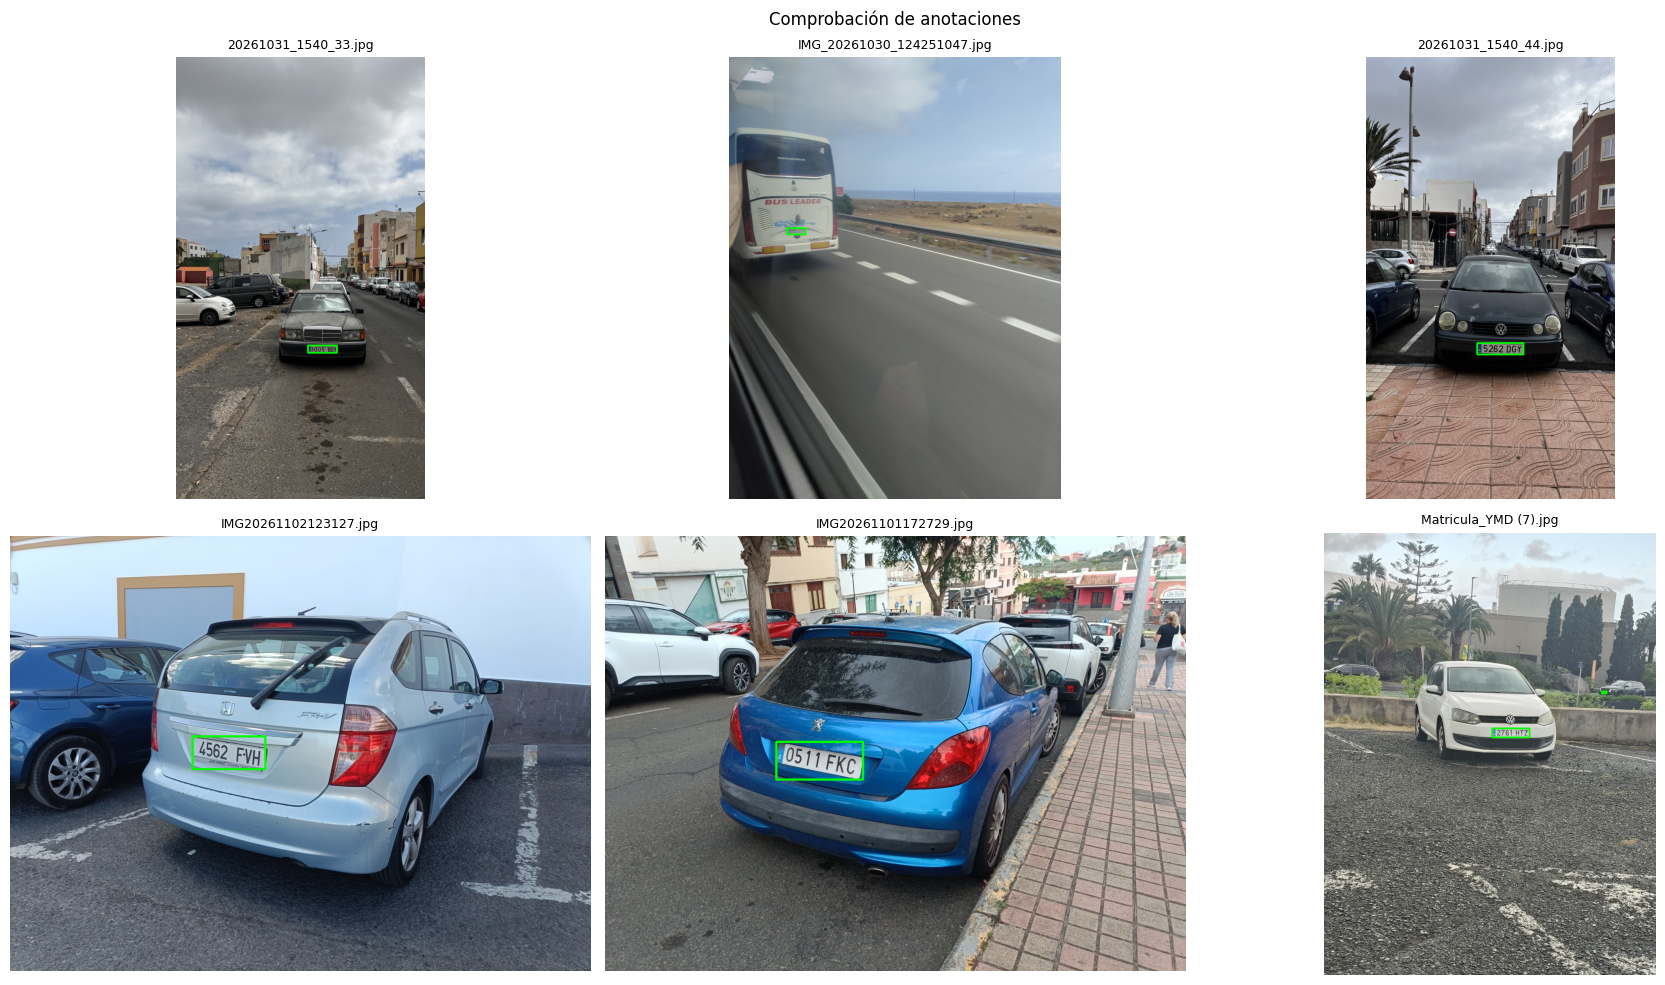

In [ ]:
# 4. Comprobación visual de las anotaciones
muestras = random.sample(sorted((OUTPUT_DIR / "images" / "train").iterdir()), 6)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, img_path in zip(axes.flat, muestras):
    ax.imshow(dibujar_etiquetas(img_path, OUTPUT_DIR / "labels" / "train" / f"{img_path.stem}.txt"))
    ax.set_title(img_path.name, fontsize=9)
    ax.axis("off")
plt.suptitle("Comprobación de anotaciones")
plt.tight_layout()
plt.show()

In [42]:
# 5. Entrenamiento o carga del modelo
if ENTRENAR:
    model = YOLO(MODELO_BASE)            # parte de los pesos de COCO (fine-tuning)
    model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        patience=PATIENCE,
        imgsz=IMGSZ,
        batch=BATCH,
        device=DEVICE,
        workers=WORKERS,
        seed=SEED,
        project=str(RUNS_DIR),
        name=RUN_NAME,
        exist_ok=False,                  # si el nombre existe crea RUN_NAME2, RUN_NAME3...
        plots=True,
    )
    TRAIN_DIR = Path(model.trainer.save_dir)
else:
    tabla_runs = listar_entrenamientos()
    display(tabla_runs)
    TRAIN_DIR = RUNS_DIR / (RUN_A_CARGAR or tabla_runs.loc[0, "carpeta"])
 
BEST_PT = TRAIN_DIR / "weights" / "best.pt"   # pesos de la mejor época (no la última)
best_model = YOLO(BEST_PT)
print("Modelo cargado:", BEST_PT)

,carpeta,épocas,mejor mAP50,mejor mAP50-95
0,matriculas_yolo11n_1280_min001,120,0.85974,0.50583


Modelo cargado: C:\Users\alici\Downloads\VC\P4\runs\matriculas_yolo11n_1280_min001\weights\best.pt


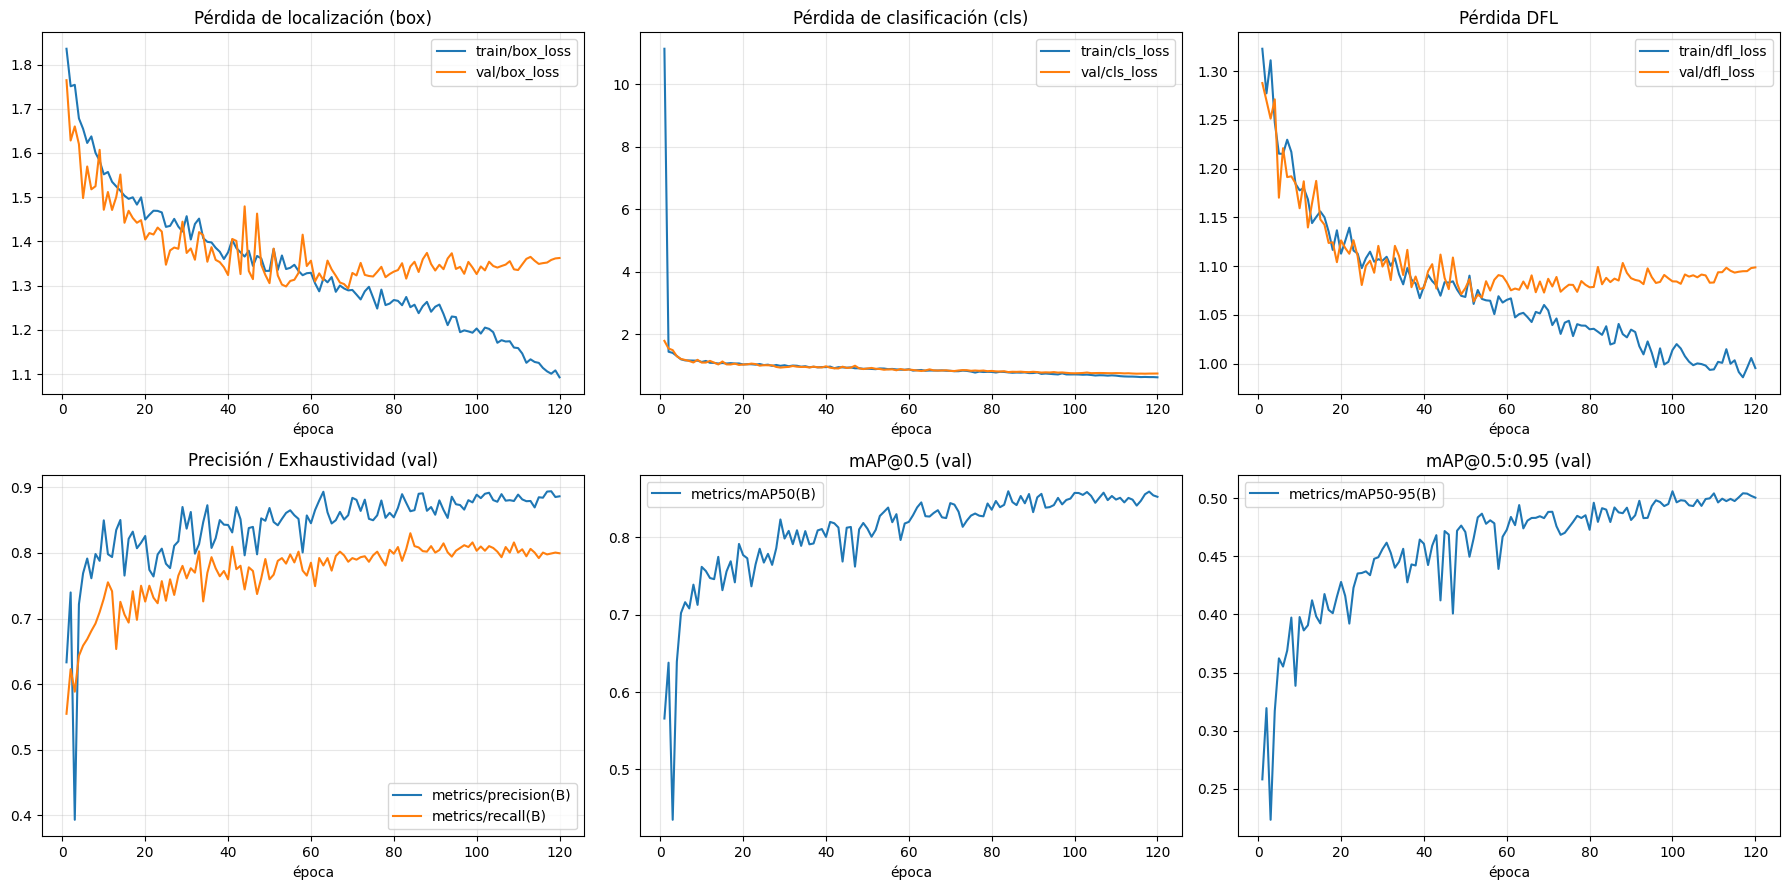

Épocas entrenadas: 120 | mejor época: 100 (mAP50 = 0.858, mAP50-95 = 0.506)


In [ ]:
# 6. Curvas de entrenamiento
df = pd.read_csv(TRAIN_DIR / "results.csv")
df.columns = df.columns.str.strip()
 
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
graficas = [
    (["train/box_loss", "val/box_loss"], "Pérdida de localización (box)"),
    (["train/cls_loss", "val/cls_loss"], "Pérdida de clasificación (cls)"),
    (["train/dfl_loss", "val/dfl_loss"], "Pérdida DFL"),
    (["metrics/precision(B)", "metrics/recall(B)"], "Precisión / Exhaustividad (val)"),
    (["metrics/mAP50(B)"], "mAP@0.5 (val)"),
    (["metrics/mAP50-95(B)"], "mAP@0.5:0.95 (val)"),
]
for ax, (cols, titulo) in zip(axes.flat, graficas):
    for c in cols:
        ax.plot(df["epoch"], df[c], label=c)
    ax.set_title(titulo)
    ax.set_xlabel("época")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
 
mejor = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
print(f"Épocas entrenadas: {len(df)} | mejor época: {int(mejor['epoch'])} "
      f"(mAP50 = {mejor['metrics/mAP50(B)']:.3f}, mAP50-95 = {mejor['metrics/mAP50-95(B)']:.3f})")


In [ ]:
# 7. Evaluación en validación y test
res = {split: evaluar(best_model, split) for split in ["val", "test"]}
 
tabla = pd.DataFrame(res)
display(tabla.drop(index=["_dir_curvas", "_dir_conf"]).astype(float).round(3))

,val,test
Precisión,0.882,0.873
Exhaustividad (recall),0.803,0.806
F1,0.841,0.838
mAP@0.5,0.853,0.837
mAP@0.5:0.95,0.510,0.493
Imágenes,358.000,359.000
Matrículas reales,712.000,700.000
TP (conf=0.35),594.000,584.000
FP (conf=0.35),81.000,82.000
FN (conf=0.35),118.000,116.000


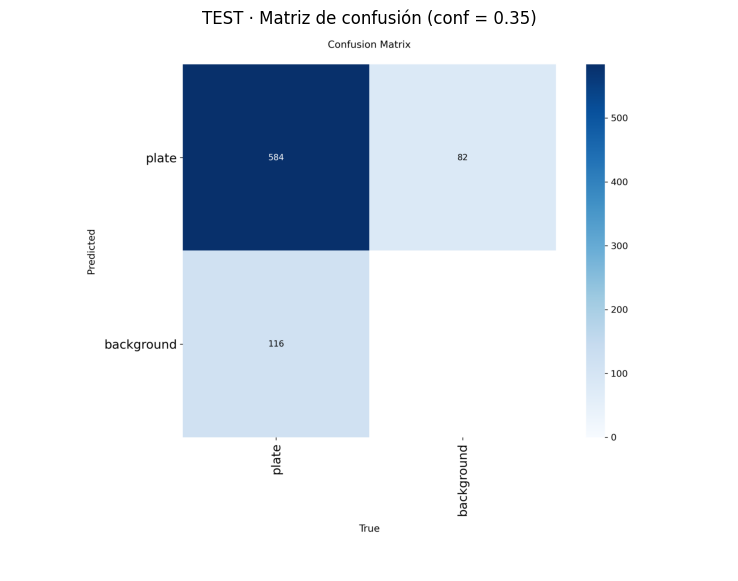

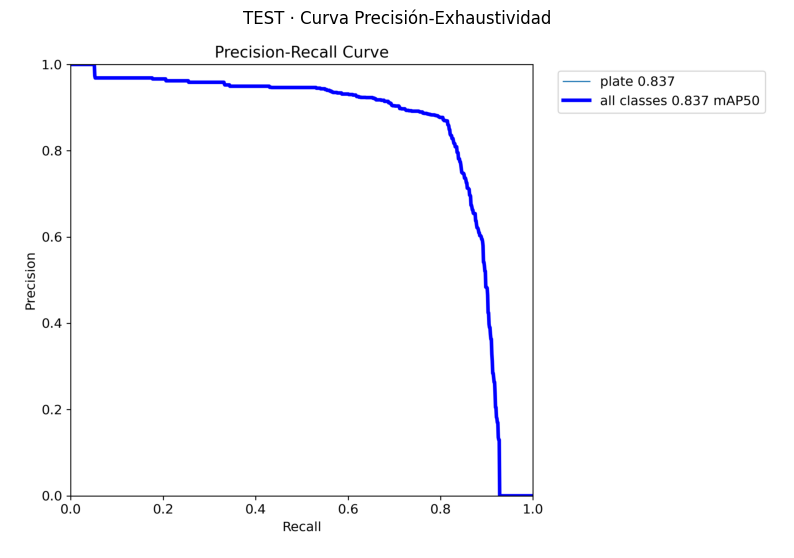

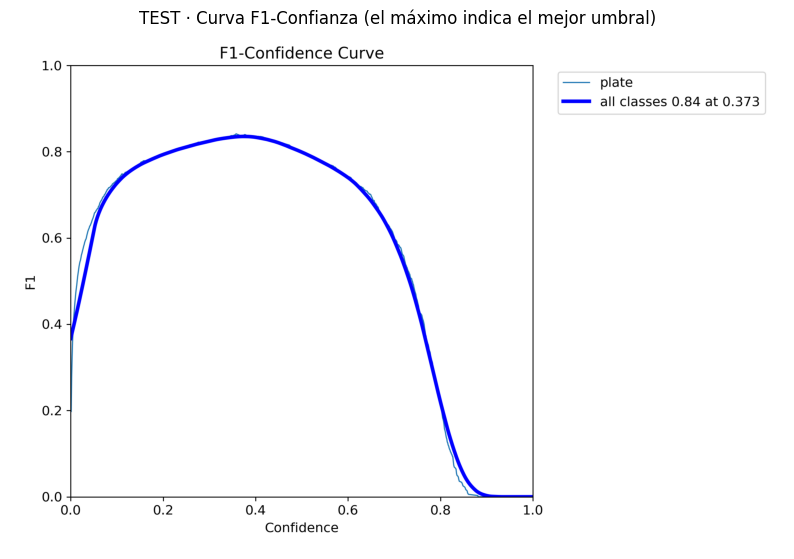

In [ ]:
# 8. Gráficas de evaluación en TEST
dir_curvas = Path(res["test"]["_dir_curvas"])
dir_conf = Path(res["test"]["_dir_conf"])
 
mostrar_png(dir_conf / "confusion_matrix.png", f"TEST · Matriz de confusión (conf = {CONF_UMBRAL})")
mostrar_png(dir_curvas / "BoxPR_curve.png", "TEST · Curva Precisión-Exhaustividad")
mostrar_png(dir_curvas / "BoxF1_curve.png", "TEST · Curva F1-Confianza (el máximo indica el mejor umbral)")
 

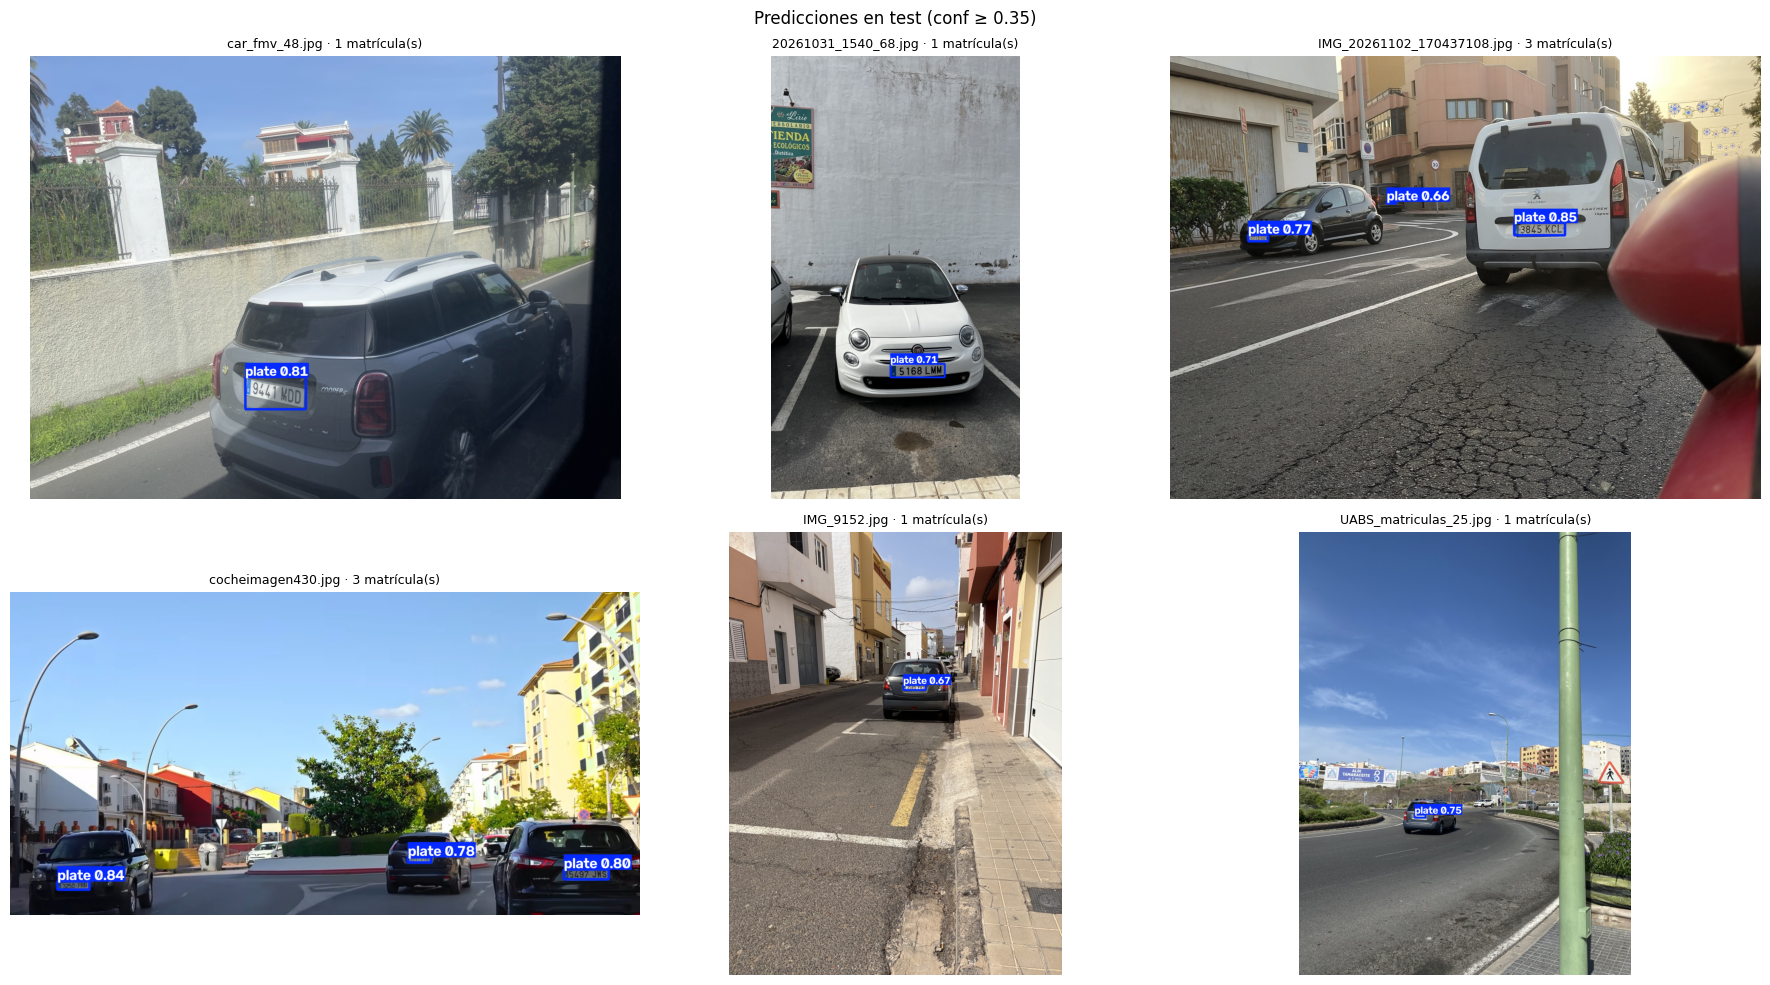

In [36]:
# 9. Ejemplos de predicciones en TEST
test_imgs = sorted((OUTPUT_DIR / "images" / "test").iterdir())
muestras_test = random.sample(test_imgs, 6)
preds = best_model.predict([str(p) for p in muestras_test], conf=CONF_UMBRAL,
                           imgsz=IMGSZ, device=DEVICE, verbose=False)
 
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, r in zip(axes.flat, preds):
    ax.imshow(r.plot()[:, :, ::-1])          # plot() devuelve BGR -> RGB
    ax.set_title(f"{Path(r.path).name} · {len(r.boxes)} matrícula(s)", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Predicciones en test (conf ≥ {CONF_UMBRAL})")
plt.tight_layout()
plt.show()

In [41]:
# 10. Exhaustividad según el tamaño de la matrícula
def iou(a, b):
    """Intersección sobre unión de dos cajas (x1, y1, x2, y2)."""
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0
 
 
filas = []
for r in best_model.predict(str(OUTPUT_DIR / "images" / "test"), conf=CONF_UMBRAL, imgsz=IMGSZ,
                            device=DEVICE, stream=True, verbose=False):
    H, W = r.orig_shape
    pred = r.boxes.xyxy.cpu().numpy()
    usados = set()
    for linea in (OUTPUT_DIR / "labels" / "test" / f"{Path(r.path).stem}.txt").read_text().splitlines():
        _, xc, yc, w, h = map(float, linea.split())
        real = [(xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H]
        ious = [iou(real, p) for p in pred]
        j = int(np.argmax(ious)) if ious else -1
        ok = j >= 0 and ious[j] >= 0.5 and j not in usados
        if ok:
            usados.add(j)
        filas.append({"ancho_px": w * W * IMGSZ / max(W, H), "detectada": ok})
 
df_err = pd.DataFrame(filas)
df_err["tamaño"] = pd.cut(df_err["ancho_px"], [0, 20, 40, 80, 10_000],
                          labels=["<20 px", "20-40 px", "40-80 px", ">80 px"])
display(df_err.groupby("tamaño", observed=False)["detectada"]
        .agg(exhaustividad="mean", matriculas="count").round(3))

,exhaustividad,matriculas
tamaño,,
<20 px,0.520,148
20-40 px,0.860,171
40-80 px,0.864,169
>80 px,0.953,212
